Question 67. Train a decision tree classifier to predict Purchase and visualise the tree.

Original dataset:


,ID,Age,Income,Spending Score,Region,Category,Visits,Online Time,Purchase,Rating
0,1,22,25000,65,North,Grocery,5,12,Yes,4.2
1,2,35,55000,40,West,Electronics,2,8,No,3.8
2,3,28,32000,70,South,Clothing,6,15,Yes,4.5
3,4,45,75000,30,East,Grocery,3,6,No,3.5
4,5,30,60000,80,South,Electronics,7,18,Yes,4.8
5,6,26,40000,55,North,Clothing,4,10,Yes,4.1
6,7,38,50000,45,West,Grocery,3,9,No,3.9
7,8,29,45000,75,South,Electronics,6,16,Yes,4.6
8,9,50,80000,35,West,Clothing,2,5,No,3.6
9,10,33,52000,60,North,Grocery,5,11,Yes,4.3


Test accuracy: 1.000
              precision    recall  f1-score   support

          No       1.00      1.00      1.00         1
         Yes       1.00      1.00      1.00         2

    accuracy                           1.00         3
   macro avg       1.00      1.00      1.00         3
weighted avg       1.00      1.00      1.00         3



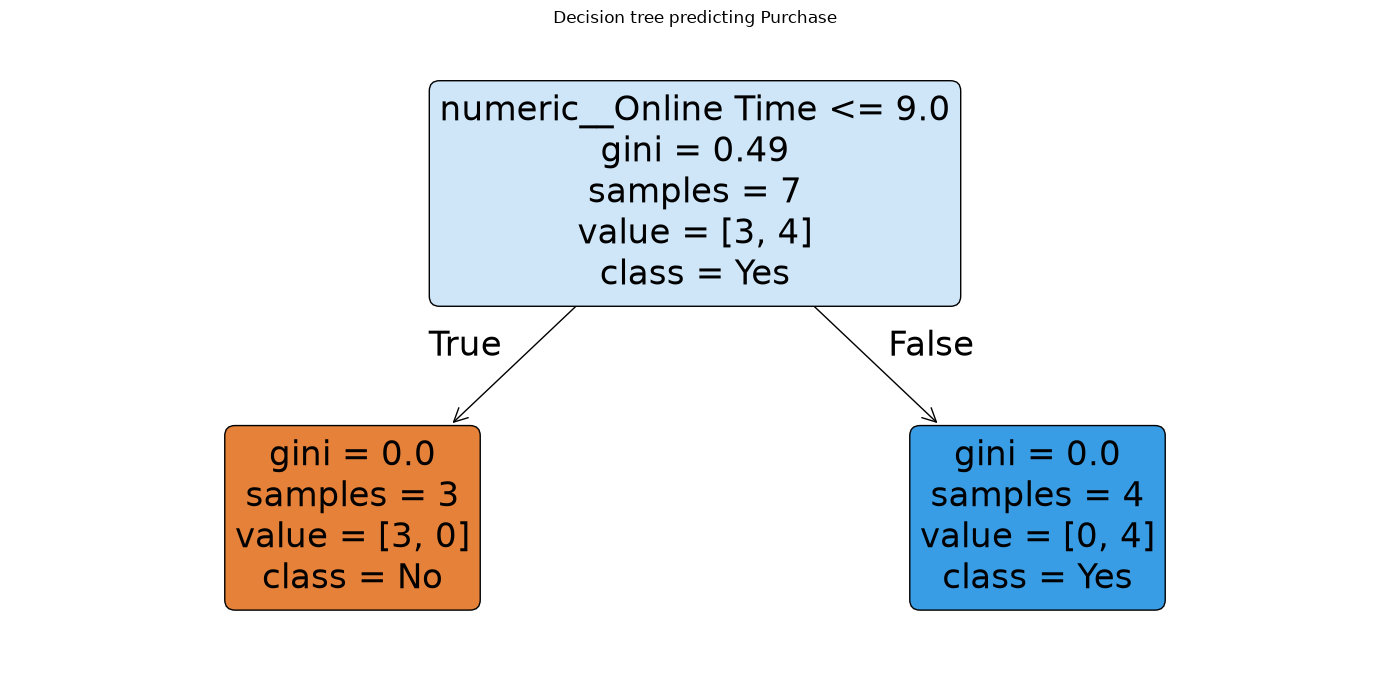

Saved question67_plot.png


In [1]:
# Step 1: Import the libraries needed for this program.
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Step 2: Load the CSV file from this question's folder into a DataFrame (table).
df = pd.read_csv("Customer_PurchaseData.csv")
print("Original dataset:")
display(df)

# Step 3: Separate predictors from Purchase; exclude ID and potentially post-purchase Rating.
X = df.drop(columns=["ID", "Purchase", "Rating"])
y = df["Purchase"]

# Step 4: List numeric and categorical predictor columns.
numeric = ["Age", "Income", "Spending Score", "Visits", "Online Time"]
categorical = ["Region", "Category"]

# Step 5: Reserve three rows as a stratified test set using a fixed random seed.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# Step 6: Pass numeric values through and encode categories using training data only.
preprocessor = ColumnTransformer([
    ("numeric", "passthrough", numeric),
    ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical),
])



# Step 7: Combine preprocessing with a reproducible decision tree.
model = Pipeline([("preprocess", preprocessor),
                  ("classifier", DecisionTreeClassifier(max_depth=3, random_state=42))])

# Step 8: Train the model, predict test outcomes and report test performance.
model.fit(X_train, y_train)
predicted = model.predict(X_test)
print(f"Test accuracy: {accuracy_score(y_test, predicted):.3f}")
print(classification_report(y_test, predicted, zero_division=0))

# Step 9: Get the encoded feature names and draw the trained tree.
names = model.named_steps["preprocess"].get_feature_names_out()
fig, ax = plt.subplots(figsize=(14, 7))
plot_tree(model.named_steps["classifier"], feature_names=names,
          class_names=model.named_steps["classifier"].classes_, filled=True, rounded=True, ax=ax)
ax.set_title("Decision tree predicting Purchase")

# Step 10: Save actual and predicted test purchases.
pd.DataFrame({"ID": df.loc[X_test.index, "ID"], "Actual": y_test, "Predicted": predicted}).to_csv("test_predictions.csv", index=False)

# Final step: Arrange labels, save the chart and display it below this cell.
fig.tight_layout()
fig.savefig("question67_plot.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Saved question67_plot.png")


Interpretation / method

ID is an identifier and is excluded. Rating is also excluded because it may only be known after a purchase; this avoids potential target leakage. Categorical encoding is fitted only on the training data. The fixed, stratified split has seven training and three test rows; accuracy on three rows is only an illustration, not reliable evidence of generalisation.